# S2 · Feature pipeline: experiments and sanity checks

Reads `data/validated/` and `data/features/`. Sections:
1. Completeness: how much of a day is known on later mornings
2. Promotion lead window
3. Feature tables: size and missing values
4. Which clues carry signal, by horizon
5. What point-in-time correctness is worth: as-of vs final-data features
6. Seasonal-naive sanity check (not a model result; that's S3)

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore", category=RuntimeWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
from palletcast.features import build as fb
from palletcast.features.asof import known_by_lag

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "axes.titlelocation": "left"})
FCFG = yaml.safe_load(open(ROOT / "configs" / "features.yaml"))
V = ROOT / "data" / "validated"
site = pd.read_parquet(ROOT / "data" / "features" / "site.parquet")
cust = pd.read_parquet(ROOT / "data" / "features" / "customer.parquet")

## 1. Completeness: how much of a day's volume is known k mornings later (06:00)

,0.01,0.05,0.5,exact
k,,,,
1,0.864,0.913,0.972,0.214
2,0.869,0.917,0.974,0.235
3,0.872,0.923,0.977,0.266
5,0.896,0.935,0.984,0.354
7,0.909,0.951,1.000,0.500
10,0.963,0.977,1.000,0.843
14,1.000,1.000,1.000,1.000
21,1.000,1.000,1.000,1.000


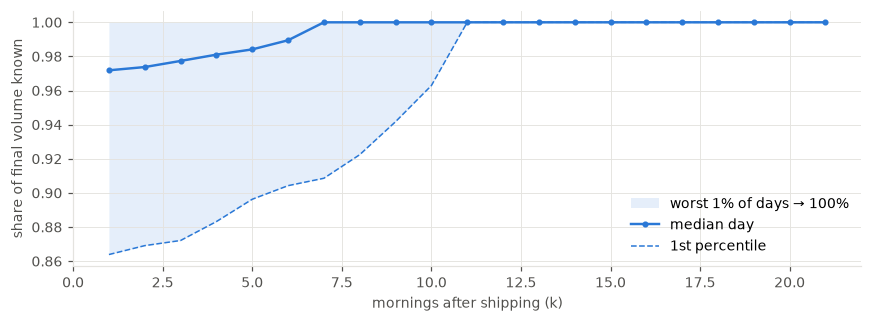

In [2]:
v = pd.read_parquet(V / "shipment_versions.parquet")
known, final = known_by_lag(v, ["site_id"], FCFG["forecast_cutoff_hour"], 21)
ok = final > 0
frac = known[ok].div(final[ok], axis=0)
q = frac.quantile([0.01, 0.05, 0.5]).T
q["exact"] = known[ok].eq(final[ok], axis=0).mean()
fig, ax = plt.subplots(figsize=(8, 3))
ax.fill_between(q.index, q[0.01], 1, color=SERIES[0], alpha=0.12, lw=0, label="worst 1% of days → 100%")
ax.plot(q.index, q[0.5], color=SERIES[0], marker="o", ms=3, label="median day")
ax.plot(q.index, q[0.01], color=SERIES[0], ls="--", lw=1, label="1st percentile")
ax.set_xlabel("mornings after shipping (k)"); ax.set_ylabel("share of final volume known")
ax.legend(frameon=False, loc="lower right"); fig.tight_layout(); fig.savefig(FIG / "s2_completeness.png")
q.loc[[1, 2, 3, 5, 7, 10, 14, 21]].round(3)

Yesterday is ~97% known (median), and the worst 1% of days only 86%. Days are final by about two weeks, and exactly final by 21 days, which is the `asof_window_days` setting (also asserted in `tests/test_features.py`).
**Decision:** use recent days, but as they looked on the forecast morning. Training and live forecasting then see the same kind of incomplete numbers.

## 2. Promotion lead window (estimated on 2023-03 … 2024-08 only)

promotions: 321 | lifted window (k): [-8, 7]


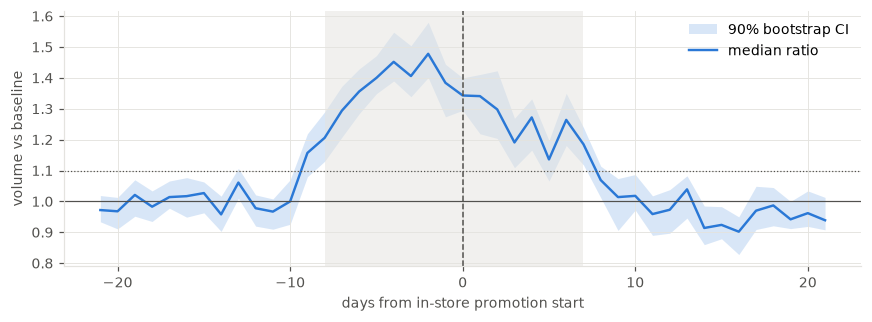

In [3]:
pl = json.loads((ROOT / "reports" / "features" / "promo_lead.json").read_text())
b = pd.DataFrame(pl["by_offset"]).set_index("k")
fig, ax = plt.subplots(figsize=(8, 3))
ax.fill_between(b.index, b.ci_lo, b.ci_hi, color=SERIES[0], alpha=0.18, lw=0, label="90% bootstrap CI")
ax.plot(b.index, b["median"], color=SERIES[0], label="median ratio")
ax.axhline(1, color=INK2, lw=0.8); ax.axhline(pl["min_uplift"], color=INK2, lw=0.8, ls=":")
lo, hi = pl["window"]; ax.axvspan(lo, hi, color=GRID, alpha=0.5, lw=0)
ax.axvline(0, color=INK2, ls="--", lw=1)
ax.set_xlabel("days from in-store promotion start"); ax.set_ylabel("volume vs baseline")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "s2_promo_lead.png")
print("promotions:", pl["n_promos"], "| lifted window (k):", pl["window"])

The shaded band marks the days where the whole confidence interval sits above 1.1×: from 8 days before to 7 days after the in-store start. After that comes a dip (~0.9× at +14 to +16). These became `promo_lift_offsets: [-7, 8]` and `promo_post_offsets: [-16, -8]` (as *start − target day*). The windows were set from data the S3 backtests won't test on, not from the simulator's settings.

## 3. Feature tables

In [4]:
for name, df in (("site", site), ("customer", cust)):
    print(f"{name:9s} rows {len(df):>8,} | series {df.iloc[:, 1 if name=='customer' else 0].nunique():>3} | "
          f"origins {df.origin.nunique():,} | target missing (outage/partial days) {df.target.isna().sum():,}")
print(site.groupby("period").size().to_string())
na = pd.concat([site.isna().mean().rename("site"), cust.isna().mean().rename("customer")], axis=1)
na[(na > 0).any(axis=1)].round(3)

site      rows   63,515 | series   4 | origins 1,309 | target missing (outage/partial days) 532
customer  rows  631,797 | series 984 | origins 1,309 | target missing (outage/partial days) 5,250
period
history    50159
live       13356


,site,customer
sw_lag1,0.032,0.032
sw_lag2,0.032,0.033
sw_lag3,0.032,0.032
sw_lag4,0.033,0.033
last_1,0.027,0.027
trend_28,0.000,0.002
target,0.008,0.008
days_since_onboard,NaN,0.968
days_to_churn,NaN,1.000
promo_next_start,NaN,0.637


Missing values are expected and meaningful. Lags are missing when the lag day was an outage or a holiday closure (masked on purpose). `trend_28` is missing for the first origins, before 56 days of history exist. `promo_next_start` is missing when no announced promotion is near. `days_since_onboard` / `days_to_churn` are missing when they don't apply. Our S3 model (gradient-boosted trees) handles missing values natively.

## 4. Which clues carry signal, by horizon (history period, Spearman correlation with target)

,sw_lag1,sw_mean4,sw_mean8,mean_28,last_1,dow
h,,,,,,
1,0.886,0.902,0.903,0.486,0.020,-0.544
2,0.887,0.903,0.903,0.483,0.056,-0.545
3,0.887,0.903,0.903,0.480,0.053,-0.546
4,0.886,0.902,0.903,0.477,0.041,-0.544
5,0.886,0.902,0.903,0.476,0.607,-0.544
6,0.883,0.902,0.903,0.474,0.883,-0.544
7,0.868,0.890,0.895,0.471,0.312,-0.545
8,0.868,0.890,0.895,0.469,-0.001,-0.545
9,0.868,0.890,0.895,0.466,0.039,-0.546


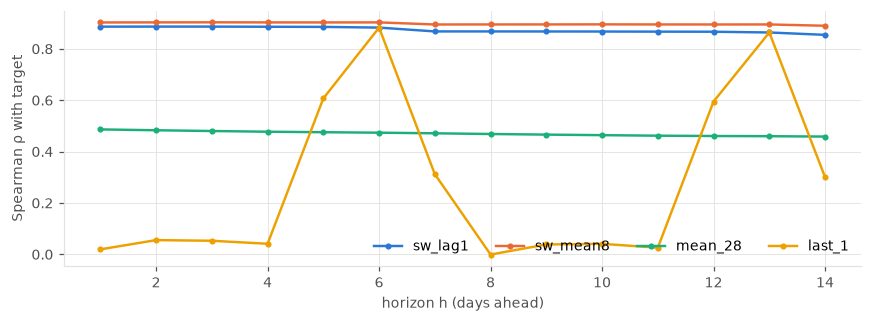

In [5]:
feats = ["sw_lag1", "sw_mean4", "sw_mean8", "mean_28", "last_1", "dow"]
hist = site[(site.period == "history") & site.target.notna()]
rho = pd.DataFrame({f: hist.groupby("h").apply(lambda g: g[f].corr(g.target, method="spearman")) for f in feats})
fig, ax = plt.subplots(figsize=(8, 3))
for i, f in enumerate(["sw_lag1", "sw_mean8", "mean_28", "last_1"]):
    ax.plot(rho.index, rho[f], color=SERIES[i], marker="o", ms=3, label=f)
ax.set_xlabel("horizon h (days ahead)"); ax.set_ylabel("Spearman ρ with target")
ax.legend(frameon=False, ncol=4); fig.tight_layout(); fig.savefig(FIG / "s2_signal_by_h.png")
rho.round(3)

Same-weekday features carry most of the signal. They're strong at every horizon because they always compare like with like (a Tuesday with Tuesdays). `last_1` (yesterday) is weak *on average* because yesterday is usually a different weekday. It's strong only when it falls on the target's weekday (h = 6, 13) or next to it (h = 5, 12). `mean_28` mixes all weekdays. Promotion and holiday features matter for *specific* days rather than on average, so a plain correlation understates them. S3's feature importance will show their real contribution.

## 5. What point-in-time correctness is worth
Rebuild the same features as if every record had arrived instantly and never been corrected (the naive way). Compare with the honest as-of features.

In [6]:
inp = fb.load_inputs(V)
naive = dict(inp)
nv = inp["versions"].sort_values(["shipment_id", "ingested_at"]).drop_duplicates("shipment_id", keep="last").copy()
nv["ingested_at"] = nv["ship_date"]          # everything known immediately, final values
naive["versions"] = nv
naive["flags"] = inp["flags"].assign(date=inp["flags"]["date"])  # same flags
origins = pd.date_range("2024-01-01", "2025-12-17", freq="D")
honest, _ = fb.build(inp, FCFG, origins=origins)
cheat, _ = fb.build(naive, FCFG, origins=origins)
k = ["site_id", "origin", "h"]
m = honest.set_index(k)[["last_1", "mean_7", "sw_lag1"]].join(cheat.set_index(k)[["last_1", "mean_7", "sw_lag1"]], rsuffix="_naive")
for f in ["last_1", "mean_7", "sw_lag1"]:
    r = (m[f] / m[f + "_naive"]).replace([np.inf, -np.inf], np.nan).dropna()
    print(f"{f:8s} as-of ÷ naive: median {r.median():.3f}  mean {r.mean():.3f}  5th pct {r.quantile(.05):.3f}  share≠ {np.mean(r != 1):.1%}")

last_1   as-of ÷ naive: median 0.972  mean 0.967  5th pct 0.912  share≠ 79.0%
mean_7   as-of ÷ naive: median 0.976  mean 0.976  5th pct 0.960  share≠ 99.9%
sw_lag1  as-of ÷ naive: median 0.982  mean 0.976  5th pct 0.926  share≠ 67.4%


In real use, yesterday's figure (`last_1`) arrives ~3% short on a typical morning and over 10% short on bad days. A model trained on the naive (final) values would expect complete numbers and then get short ones live. That's **training–serving skew**, and it biases short-horizon forecasts downwards. S3 will measure the cost as an ablation (train naive, evaluate as-of).

## 6. Seasonal-naive sanity check
Use a feature directly as the forecast. *Not a model result*: it only confirms the features line up with the target and gives S3 its first baseline.

In [7]:
def wape(y, p):
    ok = ~(np.isnan(y) | np.isnan(p)); return np.abs(y[ok] - p[ok]).sum() / y[ok].sum()
rows = []
for h, g in hist.groupby("h"):
    rows.append({"h": h, **{f: wape(g.target.to_numpy(), g[f].to_numpy()) for f in ["sw_lag1", "sw_mean4", "sw_median8"]}})
w = pd.DataFrame(rows).set_index("h")
w.round(3).T

h,1,2,3,4,5,6,7,8,9,10,11,12,13,14
sw_lag1,0.160,0.160,0.161,0.161,0.161,0.163,0.177,0.177,0.177,0.177,0.178,0.178,0.179,0.184
sw_mean4,0.146,0.146,0.146,0.146,0.146,0.146,0.155,0.155,0.155,0.155,0.155,0.155,0.155,0.160
sw_median8,0.143,0.143,0.143,0.143,0.143,0.143,0.148,0.148,0.148,0.148,0.148,0.148,0.148,0.151


**WAPE** (weighted absolute percentage error) = total absolute error ÷ total actual volume. 0.15 means "off by 15% of volume" on aggregate. Simple same-weekday rules land at roughly 14–18%, slightly worse at longer horizons. Averaging several weeks beats last week alone because it smooths noise, and the 8-week median (`sw_median8`, ~14–15%) is the best simple rule. **That's the bar S3's model must clearly beat.**